In [ ]:
initial_state = (
    1, 2, 3,
    0, 4, 6,
    7, 5, 8
)

goal_state = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

def display(state):
    for i in range(0, 9, 3):
        print(*state[i:i+3])
    print()

print("Initial State:")
display(initial_state)

print("Goal State:")
display(goal_state)

Initial State:
1 2 3
0 4 6
7 5 8

Goal State:
1 2 3
4 5 6
7 8 0



In [ ]:
def get_neighbors(state):
    neighbors = []

    blank = state.index(0)
    row, col = divmod(blank, 3)

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    for dr, dc, action in moves:
        new_row = row + dr
        new_col = col + dc

        if 0 <= new_row < 3 and 0 <= new_col < 3:
            new_blank = new_row * 3 + new_col

            board = list(state)
            board[blank], board[new_blank] = (
                board[new_blank], board[blank]
            )

            neighbors.append((tuple(board), action))

    return neighbors

In [ ]:
def dfs(initial, goal, max_depth=30):
    stack = [(initial, [], 0)]
    visited_depth = {initial: 0}

    while stack:
        state, path, depth = stack.pop()

        if state == goal:
            return path

        if depth >= max_depth:
            continue

        neighbors = get_neighbors(state)

        # Reverse so the first listed move is explored first
        for next_state, action in reversed(neighbors):
            next_depth = depth + 1

            if visited_depth.get(next_state, float("inf")) <= next_depth:
                continue

            visited_depth[next_state] = next_depth
            stack.append((
                next_state,
                path + [(action, next_state)],
                next_depth
            ))

    return None

In [ ]:
solution = dfs(initial_state, goal_state)

if solution is None:
    print("No solution found within the depth limit.")
else:
    print("Initial State:")
    display(initial_state)

    for step, (action, state) in enumerate(solution, start=1):
        print(f"Step {step}: Move blank {action}")
        display(state)

    print("Total moves:", len(solution))

Initial State:
1 2 3
0 4 6
7 5 8

Step 1: Move blank UP
0 2 3
1 4 6
7 5 8

Step 2: Move blank RIGHT
2 0 3
1 4 6
7 5 8

Step 3: Move blank DOWN
2 4 3
1 0 6
7 5 8

Step 4: Move blank DOWN
2 4 3
1 5 6
7 0 8

Step 5: Move blank LEFT
2 4 3
1 5 6
0 7 8

Step 6: Move blank UP
2 4 3
0 5 6
1 7 8

Step 7: Move blank UP
0 4 3
2 5 6
1 7 8

Step 8: Move blank RIGHT
4 0 3
2 5 6
1 7 8

Step 9: Move blank DOWN
4 5 3
2 0 6
1 7 8

Step 10: Move blank DOWN
4 5 3
2 7 6
1 0 8

Step 11: Move blank LEFT
4 5 3
2 7 6
0 1 8

Step 12: Move blank UP
4 5 3
0 7 6
2 1 8

Step 13: Move blank RIGHT
4 5 3
7 0 6
2 1 8

Step 14: Move blank DOWN
4 5 3
7 1 6
2 0 8

Step 15: Move blank LEFT
4 5 3
7 1 6
0 2 8

Step 16: Move blank UP
4 5 3
0 1 6
7 2 8

Step 17: Move blank UP
0 5 3
4 1 6
7 2 8

Step 18: Move blank RIGHT
5 0 3
4 1 6
7 2 8

Step 19: Move blank DOWN
5 1 3
4 0 6
7 2 8

Step 20: Move blank DOWN
5 1 3
4 2 6
7 0 8

Step 21: Move blank LEFT
5 1 3
4 2 6
0 7 8

Step 22: Move blank UP
5 1 3
0 2 6
4 7 8

Step 23: Move bla

Nodes visited: 12
Solution found: True
Solution depth: 11


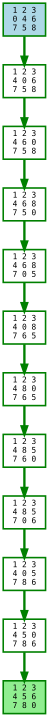

In [ ]:
from graphviz import Digraph

def dfs_visual(initial, goal, max_depth=30, max_nodes=500):
    graph = Digraph("DFS")
    graph.attr(rankdir="TB", size="12,10")
    graph.attr("node", shape="box", fontname="monospace",
               fontsize="10")

    node_count = 0
    solution_path = []
    stopped = False

    def label(state):
        return (
            f"{state[0]} {state[1]} {state[2]}\n"
            f"{state[3]} {state[4]} {state[5]}\n"
            f"{state[6]} {state[7]} {state[8]}"
        )

    def search(state, depth, path_states, parent_id=None, action=None):
        nonlocal node_count, solution_path, stopped

        if node_count >= max_nodes:
            stopped = True
            return False

        node_count += 1
        node_id = f"n{node_count}"

        attrs = {"label": label(state)}

        if state == initial:
            attrs.update(style="filled", fillcolor="lightblue")
        elif state == goal:
            attrs.update(style="filled", fillcolor="lightgreen")

        graph.node(node_id, **attrs)

        if parent_id is not None:
            edge_attrs = {"label": action}

            if solution_path and parent_id in solution_path:
                edge_attrs.update(color="green", penwidth="3")

                graph.edge(parent_id, node_id, **edge_attrs)

        if state == goal:
            solution_path.append(node_id)
            return True

        if depth >= max_depth:
            return False

        # Move ordering controls which branch DFS explores first.
        priority = {"RIGHT": 0, "DOWN": 1, "UP": 2, "LEFT": 3}

        neighbors = sorted(
            get_neighbors(state),
            key=lambda item: priority[item[1]]
        )

        for next_state, move in neighbors:
            if next_state in path_states:
                continue

            path_states.add(next_state)

            if search(
                next_state, depth + 1, path_states,
                node_id, move
            ):
                solution_path.append(node_id)
                return True

            path_states.remove(next_state)

            if stopped:
                return False

        return False

    found = search(initial, 0, {initial})

    # The path is stored backwards: goal -> ... -> root.
    solution_path.reverse()

    # Highlight only the real solution nodes and their existing edges.
    if found:
        for node_id in solution_path:
            graph.node(node_id, color="green", penwidth="2")

        for parent, child in zip(
            solution_path, solution_path[1:]
        ):
            graph.edge(
                parent, child,
                color="green",
                penwidth="3"
            )

    print("Nodes visited:", node_count)
    print("Solution found:", found)

    if stopped:
        print("Search stopped at the node limit.")

    if found:
        print("Solution depth:", len(solution_path) - 1)

    return graph, solution_path


graph, solution_path = dfs_visual(
    initial_state,
    goal_state,
    max_depth=30,
    max_nodes=500
)

graph